<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">


# Procesamiento de lenguaje natural
## Custom embedddings con Gensim



### Objetivo
El objetivo es utilizar documentos / corpus para crear embeddings de palabras basado en ese contexto. Se utilizará canciones de bandas para generar los embeddings, es decir, que los vectores tendrán la forma en función de como esa banda haya utilizado las palabras en sus canciones.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import multiprocessing
try:
  from gensim.models import Word2Vec
except:
  !pip install gensim
  from gensim.models import Word2Vec

### Datos
Utilizaremos como dataset canciones de bandas de habla inglesa.

In [2]:
# Descargar la carpeta de dataset
import os
import platform
#if os.access('./songs_dataset', os.F_OK) is False:
#    if os.access('songs_dataset.zip', os.F_OK) is False:
#        if platform.system() == 'Windows':
#            !curl https://raw.githubusercontent.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/main/datasets/songs_dataset.zip -o songs_dataset.zip
#        else:
#            !wget songs_dataset.zip https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/raw/main/datasets/songs_dataset.zip
#    !unzip -q songs_dataset.zip
#else:
#    print("El dataset ya se encuentra descargado")

In [3]:
# Posibles bandas
os.listdir("./songs_dataset/")

['adele.txt',
 'al-green.txt',
 'alicia-keys.txt',
 'amy-winehouse.txt',
 'beatles.txt',
 'bieber.txt',
 'bjork.txt',
 'blink-182.txt',
 'bob-dylan.txt',
 'bob-marley.txt',
 'britney-spears.txt',
 'bruce-springsteen.txt',
 'bruno-mars.txt',
 'cake.txt',
 'dickinson.txt',
 'disney.txt',
 'dj-khaled.txt',
 'dolly-parton.txt',
 'dr-seuss.txt',
 'drake.txt',
 'eminem.txt',
 'janisjoplin.txt',
 'jimi-hendrix.txt',
 'johnny-cash.txt',
 'joni-mitchell.txt',
 'kanye-west.txt',
 'kanye.txt',
 'Kanye_West.txt',
 'lady-gaga.txt',
 'leonard-cohen.txt',
 'lil-wayne.txt',
 'Lil_Wayne.txt',
 'lin-manuel-miranda.txt',
 'lorde.txt',
 'ludacris.txt',
 'michael-jackson.txt',
 'missy-elliott.txt',
 'nickelback.txt',
 'nicki-minaj.txt',
 'nirvana.txt',
 'notorious-big.txt',
 'notorious_big.txt',
 'nursery_rhymes.txt',
 'patti-smith.txt',
 'paul-simon.txt',
 'prince.txt',
 'r-kelly.txt',
 'radiohead.txt',
 'rihanna.txt']

In [4]:
# Armar el dataset utilizando salto de línea para separar las oraciones/docs
df = pd.read_csv('songs_dataset/beatles.txt', sep='/n', header=None)
df.head()

C:\Users\lucas\AppData\Local\Temp\ipykernel_26692\3849064916.py:2: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv('songs_dataset/beatles.txt', sep='/n', header=None)


,0
0,"Yesterday, all my troubles seemed so far away"
1,Now it looks as though they're here to stay
2,"Oh, I believe in yesterday Suddenly, I'm not h..."
3,There's a shadow hanging over me.
4,"Oh, yesterday came suddenly Why she had to go ..."


In [5]:
print("Cantidad de documentos:", df.shape[0])

Cantidad de documentos: 1846


### 1 - Preprocesamiento

In [6]:
from tensorflow.keras.preprocessing.text import text_to_word_sequence

sentence_tokens = []
# Recorrer todas las filas y transformar las oraciones
# en una secuencia de palabras (esto podría realizarse con NLTK o spaCy también)
for _, row in df[:None].iterrows():
    sentence_tokens.append(text_to_word_sequence(row[0]))

In [7]:
# Demos un vistazo
sentence_tokens[:2]

[['yesterday', 'all', 'my', 'troubles', 'seemed', 'so', 'far', 'away'],
 ['now', 'it', 'looks', 'as', 'though', "they're", 'here', 'to', 'stay']]

### 2 - Crear los vectores (word2vec)

In [8]:
from gensim.models.callbacks import CallbackAny2Vec
# Durante el entrenamiento gensim por defecto no informa el "loss" en cada época
# Sobrecargamos el callback para poder tener esta información
class callback(CallbackAny2Vec):
    """
    Callback to print loss after each epoch
    """
    def __init__(self):
        self.epoch = 0

    def on_epoch_end(self, model):
        loss = model.get_latest_training_loss()
        if self.epoch == 0:
            print('Loss after epoch {}: {}'.format(self.epoch, loss))
        else:
            print('Loss after epoch {}: {}'.format(self.epoch, loss- self.loss_previous_step))
        self.epoch += 1
        self.loss_previous_step = loss

In [9]:
# Crearmos el modelo generador de vectores
# En este caso utilizaremos la estructura modelo Skipgram
w2v_model = Word2Vec(min_count=5,    # frecuencia mínima de palabra para incluirla en el vocabulario
                     window=2,       # cant de palabras antes y desp de la predicha
                     vector_size=300,       # dimensionalidad de los vectores
                     negative=20,    # cantidad de negative samples... 0 es no se usa
                     workers=1,      # si tienen más cores pueden cambiar este valor
                     sg=1)           # modelo 0:CBOW  1:skipgram

In [10]:
# Obtener el vocabulario con los tokens
w2v_model.build_vocab(sentence_tokens)

In [11]:
# Cantidad de filas/docs encontradas en el corpus
print("Cantidad de docs en el corpus:", w2v_model.corpus_count)

Cantidad de docs en el corpus: 1846


In [12]:
# Cantidad de words encontradas en el corpus
print("Cantidad de words distintas en el corpus:", len(w2v_model.wv.index_to_key))

Cantidad de words distintas en el corpus: 445


### 3 - Entrenar embeddings

In [13]:
# Entrenamos el modelo generador de vectores
# Utilizamos nuestro callback
w2v_model.train(sentence_tokens,
                 total_examples=w2v_model.corpus_count,
                 epochs=20,
                 compute_loss = True,
                 callbacks=[callback()]
                 )

Loss after epoch 0: 113045.2421875
Loss after epoch 1: 65966.5390625
Loss after epoch 2: 65934.96875
Loss after epoch 3: 65718.46875
Loss after epoch 4: 63875.09375
Loss after epoch 5: 64160.96875
Loss after epoch 6: 64080.34375
Loss after epoch 7: 64815.0
Loss after epoch 8: 62632.5625
Loss after epoch 9: 60452.6875
Loss after epoch 10: 59839.6875
Loss after epoch 11: 58884.1875
Loss after epoch 12: 57715.9375
Loss after epoch 13: 56494.0
Loss after epoch 14: 55817.4375
Loss after epoch 15: 55843.0
Loss after epoch 16: 51722.5
Loss after epoch 17: 49858.0
Loss after epoch 18: 49592.125
Loss after epoch 19: 48960.375


(156986, 287740)

### 4 - Ensayar

In [14]:
# Palabras que MÁS se relacionan con...:
w2v_model.wv.most_similar(positive=["darling"], topn=10)

[('pretty', 0.8954252004623413),
 ('sleep', 0.8665635585784912),
 ('help', 0.8439401388168335),
 ('cry', 0.8351266980171204),
 ('not', 0.8309596180915833),
 ('try', 0.8276923298835754),
 ('peace', 0.8144838809967041),
 ('little', 0.8140546679496765),
 ('twist', 0.8123899102210999),
 ('seems', 0.8079549670219421)]

In [15]:
# Palabras que MENOS se relacionan con...:
w2v_model.wv.most_similar(negative=["love"], topn=10)

[('shake', -0.22873109579086304),
 ('four', -0.2330222725868225),
 ('five', -0.23746439814567566),
 ('six', -0.2378462553024292),
 ('bang', -0.24832230806350708),
 ('our', -0.2553924024105072),
 ('day', -0.26898154616355896),
 ('going', -0.2692105174064636),
 ('here', -0.26990070939064026),
 ('three', -0.2838965952396393)]

In [16]:
# Palabras que MÁS se relacionan con...:
w2v_model.wv.most_similar(positive=["four"], topn=10)

[('five', 0.981372058391571),
 ('three', 0.9745771288871765),
 ('six', 0.9710806608200073),
 ('seven', 0.9584371447563171),
 ('two', 0.951723575592041),
 ('sixty', 0.8990399241447449),
 ('one', 0.7951170802116394),
 ('crying', 0.7946274876594543),
 ('us', 0.7740071415901184),
 ("i'm", 0.7508386969566345)]

In [17]:
# Palabras que MÁS se relacionan con...:
w2v_model.wv.most_similar(positive=["money"], topn=5)

[("can't", 0.9434005618095398),
 ('buy', 0.9396992921829224),
 ('much', 0.9033195376396179),
 ('just', 0.8509086966514587),
 ('hide', 0.8355351090431213)]

In [18]:
# Ensayar con una palabra que no está en el vocabulario:
# w2v_model.wv.most_similar(negative=["diedaa"])

In [19]:
# el método `get_vector` permite obtener los vectores:
vector_love = w2v_model.wv.get_vector("love")
print(vector_love)

[ 0.06138413  0.05881019 -0.06370354  0.02445617 -0.20152482 -0.18611853
 -0.15284552  0.45486635 -0.04217679  0.03535806  0.13657518 -0.18519785
 -0.18126503  0.22149378 -0.30380824 -0.23969936  0.07094827 -0.0567887
 -0.05165625 -0.2384332  -0.08529592  0.19564067 -0.07679196  0.03796551
  0.0751621  -0.0482575   0.07379384  0.10396665  0.00737955 -0.22764955
 -0.04567023  0.12936655  0.27785373  0.19387273 -0.13510206  0.20857345
  0.40917116 -0.00386532 -0.10631495 -0.09056864  0.02401222 -0.08005036
  0.13399509  0.08833685 -0.01894409  0.08592524 -0.1590568   0.10259779
  0.14459649 -0.12092511 -0.27919346 -0.04061023  0.11382007  0.31366137
 -0.0740839   0.139766    0.22791134  0.13208385 -0.0181147   0.09772249
  0.09249445 -0.14871854 -0.163485   -0.1320215  -0.09834237  0.02714372
  0.16531056  0.26052314 -0.03259229 -0.02894631  0.11621047 -0.06974225
  0.09562858 -0.15276162  0.22070931  0.15996651  0.15890568 -0.04711937
 -0.12555729 -0.03992885 -0.10795498  0.01878585  0.

In [20]:
# el método `most_similar` también permite comparar a partir de vectores
w2v_model.wv.most_similar(vector_love)

[('love', 0.9999999403953552),
 ('babe', 0.9085155129432678),
 ('someone', 0.8886152505874634),
 ('need', 0.8827986717224121),
 ('nothing', 0.8740267753601074),
 ("didn't", 0.8638384342193604),
 ("there's", 0.8526656031608582),
 ('you', 0.8456713557243347),
 ('feed', 0.8445046544075012),
 ('somebody', 0.8362797498703003)]

In [21]:
# Palabras que MÁS se relacionan con...:
w2v_model.wv.most_similar(positive=["love"], topn=10)

[('babe', 0.9085155129432678),
 ('someone', 0.8886152505874634),
 ('need', 0.8827986717224121),
 ('nothing', 0.8740267753601074),
 ("didn't", 0.8638384342193604),
 ("there's", 0.8526656627655029),
 ('you', 0.8456713557243347),
 ('feed', 0.844504714012146),
 ('somebody', 0.8362797498703003),
 ('buy', 0.8351762294769287)]

### 5 - Visualizar agrupación de vectores

In [22]:
from sklearn.decomposition import IncrementalPCA
from sklearn.manifold import TSNE
import numpy as np

def reduce_dimensions(model, num_dimensions = 2 ):

    vectors = np.asarray(model.wv.vectors)
    labels = np.asarray(model.wv.index_to_key)

    tsne = TSNE(n_components=num_dimensions, random_state=0)
    vectors = tsne.fit_transform(vectors)

    return vectors, labels

In [23]:
# Graficar los embedddings en 2D
import plotly.graph_objects as go
import plotly.express as px

vecs, labels = reduce_dimensions(w2v_model)

MAX_WORDS=200
fig = px.scatter(x=vecs[:MAX_WORDS,0], y=vecs[:MAX_WORDS,1], text=labels[:MAX_WORDS])
fig.show(renderer="colab") # esto para plotly en colab

In [24]:
# Graficar los embedddings en 3D

vecs, labels = reduce_dimensions(w2v_model,3)

fig = px.scatter_3d(x=vecs[:MAX_WORDS,0], y=vecs[:MAX_WORDS,1], z=vecs[:MAX_WORDS,2],text=labels[:MAX_WORDS])
fig.update_traces(marker_size = 2)
fig.show(renderer="colab") # esto para plotly en colab

In [25]:
# También se pueden guardar los vectores y labels como tsv para graficar en
# http://projector.tensorflow.org/


vectors = np.asarray(w2v_model.wv.vectors)
labels = list(w2v_model.wv.index_to_key)

np.savetxt("vectors.tsv", vectors, delimiter="\t")

with open("labels.tsv", "w") as fp:
    for item in labels:
        fp.write("%s\n" % item)

### Consigna del desafío 2

**Cada experimento realizado debe estar acompañado de una explicación o interpretación de lo observado, incluido el sustento de las decisiones que tomaron (como modificación de hiperparámetros)**

Recuerden que su notebook de entrega debe poder correrse de inicio a fin sin la aparición de errores.

- Crear sus propios vectores con Gensim basado en lo visto en clase con un corpus propio (revisar enlaces sugeridos en clase 2 sobre opciones de dataset)
- Elegir términos de interés y buscar términos más similares y menos similares.
- Realizar una reduccion de dimensionalidad a los embeddings, llevándolos a 2 dimensiones. Graficar los embeddings proyectados y seleccionar una cantidad de términos (variable MAX_WORDS) de forma tal que la visualización sea adecuada.
- Inspeccionar el grafico y buscar pequeños grupos de palabras que puedan formarse. Interpretarlos e intentar obtener conclusiones. En lo posible, acompañar los grupos de palabras con capturas (y pegarlas en celdas de texto)

## Corpus Harry Potter

Para el desarrollo del del desafío, voy a utilizar un corpus conformado por todos los capítulos de los primeros tres libros de Harry Potter (https://nuochenpku.github.io/HPD.github.io/). Si bien están todos, para no tener un dataset pesado seleccioné los primeros tres.

In [26]:
os.listdir("./harry_potter/")

['book_1_chapter_1.txt',
 'book_1_chapter_10.txt',
 'book_1_chapter_11.txt',
 'book_1_chapter_12.txt',
 'book_1_chapter_13.txt',
 'book_1_chapter_14.txt',
 'book_1_chapter_15.txt',
 'book_1_chapter_16.txt',
 'book_1_chapter_17.txt',
 'book_1_chapter_2.txt',
 'book_1_chapter_3.txt',
 'book_1_chapter_4.txt',
 'book_1_chapter_5.txt',
 'book_1_chapter_6.txt',
 'book_1_chapter_7.txt',
 'book_1_chapter_8.txt',
 'book_1_chapter_9.txt',
 'book_2_chapter_1.txt',
 'book_2_chapter_10.txt',
 'book_2_chapter_11.txt',
 'book_2_chapter_12.txt',
 'book_2_chapter_13.txt',
 'book_2_chapter_14.txt',
 'book_2_chapter_15.txt',
 'book_2_chapter_16.txt',
 'book_2_chapter_17.txt',
 'book_2_chapter_18.txt',
 'book_2_chapter_2.txt',
 'book_2_chapter_3.txt',
 'book_2_chapter_4.txt',
 'book_2_chapter_5.txt',
 'book_2_chapter_6.txt',
 'book_2_chapter_7.txt',
 'book_2_chapter_8.txt',
 'book_2_chapter_9.txt',
 'book_3_chapter_1.txt',
 'book_3_chapter_10.txt',
 'book_3_chapter_11.txt',
 'book_3_chapter_12.txt',
 'boo

In [27]:
from pathlib import Path

df = pd.concat(
    [pd.read_csv(f, sep="\t", header=None, names=["text"], quoting=3)
     for f in Path("harry_potter").glob("*.txt")],
    ignore_index=True,
)
df.head()

,text
0,CHAPTER ONE
1,THE BOY WHO LIVED
2,"Mr. and Mrs. Dursley, of number four, Privet D..."
3,Mr. Dursley was the director of a firm called ...
4,"The Dursleys had everything they wanted, but t..."


Para el análisis, tomo como documentos a las oraciones que conforman los capítulos del libro, es por eso que, por ejemplo, los primeros dos registros del dataset son oraciones del título del primer capítulo "CHAPTER ONE" y "THE BOY WHO LIVED". Como la cantidad de elementos es grande (lo veremos a continuación) no me molesta agregarlos en el dataset final.

In [28]:
df.shape

(10561, 1)

Vemos que en total tenemos 10561, que a comparación del dataset de ejemplo del notebook, es un corpus grande.

## Preprocesamiento
Por cada documento del dataset, voy a realizar la tokenización, es decir, voy a extraer cada palabra por separado de cada oración con la que luego vamos a construir los vectores. Para ello, voy a valerme de la misma librería utilizada en este notebook: keras con la función text_to_word_sequence

In [29]:
special_chars = special_chars = ['.', ',', '!', '?', ':', ';', '(', ')', '[', ']', '{', '}', '¿', '¡', '"', "'", "“", "’"]
custom_filters = "".join(special_chars)

sentence_tokens = []
for _, row in df[:None].iterrows():
    sentence_tokens.append(text_to_word_sequence(str(row['text']), filters=custom_filters, lower=True))


In [30]:
sentence_tokens[:2]

[['chapter', 'one'], ['the', 'boy', 'who', 'lived']]

Logramos tokenizar las dos primeras oraciones correctamente.

## Creamos los vectores con word2vec
Voy a proceder a construir el vocabulario utilizando word2vec, a continuación la instanciación junto con algunos comentarios de los parámetros elegidos.

In [31]:
w2v_model = Word2Vec(min_count=10, #Dado que tengo un corpus grande, voy a utilizar una frecuencia mínima de 10 para que una palabra sea incluida en el vocabulario
                     window=4, #Tomo mayor cantidad de palabras dado que tengo un corpus grande
                     vector_size=500, #Idem. que con el item anterior, tenemos más posibilidad de vocabulario variado, entonces podemos tener vectores de mayor dimensionalidad
                     negative=20,
                     workers=2,
                     sg=0) #Para esta prueba, selecciono CBOW para ver su comportamiento

In [32]:
w2v_model.build_vocab(sentence_tokens)
print("Cantidad de docs en el corpus:", w2v_model.corpus_count)
print("Cantidad de words distintas en el corpus:", len(w2v_model.wv.index_to_key))

Cantidad de docs en el corpus: 10561
Cantidad de words distintas en el corpus: 2372


Analizando un poco la salida, vemos que pudimos exstraer 2372 palabras del vocabulario de un total de 10561 documentos, es decir, casi el 23% de los documentos son palabras de nuestro vocabulario.

## Entrenamiento de los embeddings
Habiendo construido el vocabulario, procederemos a construir los embeddings

In [33]:
w2v_model.train(sentence_tokens,
                total_examples=w2v_model.corpus_count,
                epochs=30,
                compute_loss = True,
                callbacks=[callback()])

Loss after epoch 0: 455364.34375
Loss after epoch 1: 381001.78125
Loss after epoch 2: 328770.875
Loss after epoch 3: 318484.75
Loss after epoch 4: 311435.75
Loss after epoch 5: 305257.5
Loss after epoch 6: 271368.75
Loss after epoch 7: 267974.5
Loss after epoch 8: 264880.25
Loss after epoch 9: 262950.5
Loss after epoch 10: 259607.25
Loss after epoch 11: 257247.75
Loss after epoch 12: 257013.25
Loss after epoch 13: 235834.75
Loss after epoch 14: 233258.5
Loss after epoch 15: 228553.5
Loss after epoch 16: 227075.0
Loss after epoch 17: 226427.5
Loss after epoch 18: 224019.0
Loss after epoch 19: 206229.0
Loss after epoch 20: 221304.0


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Loss after epoch 21: 219833.5
Loss after epoch 22: 216633.5
Loss after epoch 23: 216830.5
Loss after epoch 24: 214001.0
Loss after epoch 25: 200030.5
Loss after epoch 26: 212539.0
Loss after epoch 27: 211700.5
Loss after epoch 28: 209838.5
Loss after epoch 29: 194268.0


(5686332, 8723400)

## Evaluación de términos
Voy a seleccionar algunos términos para ver con qué palabras tienen una similitud coseno alta.

#### Disclaimer: Hice un análisis previo, luego vi que aparecían algunos caracteres especiales, hice una limpieza y volví a reprocesar. Encontré nuevos términos post-entrenamiento que puede deberse tanto al preprocesamiento como al entrenamiento en si, pero me pareció interesante dejar el análisis para ver los términos que había antes vs. los nuevos que aparecieron luego de la limpieza

In [34]:
w2v_model.wv.most_similar(positive=["potter"], topn=10)

[('sir', 0.47816935181617737),
 ('famous', 0.426169753074646),
 ('business', 0.38599082827568054),
 ('prongs', 0.38406839966773987),
 ('dear', 0.3830278217792511),
 ('wormtail', 0.37426531314849854),
 ('lily', 0.3741687834262848),
 ('molly', 0.36999085545539856),
 ('ah', 0.3670161962509155),
 ('ollivander', 0.3663925230503082)]

Para las palabras que más se relacionan con "Potter", nuestro protagonista, vemos que en primer y segundo lugar aparece el término "Sir" y "Famous", tiene mucho sentido pues en los primeros dos libros nos introducen a Harry como un sujeto famoso dentro del mundo mágico dado los acontecimientos que se llevaron a cabo en su infancia. Además, dentro de los términos se encuentran "Lily" su madre y "prongs" o "cornamenta" que es el apodo que recibía James (su padre) entre sus amigos (mención especial, también aparece "wormtail" o "colagusano" que era amigo del padre de Harry"). Es lógico que aparezcan "Lily" ya que, si bien su apellido era "Evans", hasta el 6-7 libro se la solía mencionar como Lily Potter. Además, hay mucha influencia del tercer libro hacia el término Potter ya que en este aparecen varios personajes como "Sirius" y "Remus" que tenían relación con los padres de Harry y en distintas situaciones cuentan sobre su relación con ellos.


#### Disclaimer(Análisis previo a la limpieza): Vemos que entre las palabras que más se relacionan "Potter" son nombres propios como Ollivander, Dobby, Remus. En los libros primeros tres libros, son personajes con los que el protagonista tiene interacción. Curiosamente, los tres son personajes correspondientes a los tres libros respectivamente. Esto hace alusión a que hay algún personaje con el que Harry tiene más interacción en cada libro, es decir, que tiene contexto compartido. Además, aparecen términos como "named", que hace referencia a cuando hablan de "el que no debe ser nombrado" o "He Who Must Not Be Named". Esto ocurre por los múltiples diálogos en los que Harry habla con alguien sobre Voldemort. 

In [35]:
w2v_model.wv.most_similar(positive=["voldemort"], topn=10)

[('you-know-who', 0.5625882744789124),
 ('lord', 0.4815170466899872),
 ('name', 0.4342028498649597),
 ('whatever', 0.4322411119937897),
 ('powers', 0.4283220171928406),
 ('power', 0.4174509048461914),
 ('james', 0.4168834686279297),
 ('escaped', 0.4035659730434418),
 ('someone', 0.40051600337028503),
 ('potters', 0.3962387144565582)]

Cuando buscamos por voldemort, el enemigo de harry, vemos que aparecen palabras como "lord" ya que en múltiples ocasiones se suele referenciar a voldemort como "Lord voldemort", por lo que suele haber mucha compañía de estas palabras. Además los términos "you-know-who" y "name" es porque muchas veces se referencia a voldemort como "el que no debe ser nombrado" o ""He Who Must Not Be Named" dado que se creía que pronunciar su nombre traía mala suerte. Hay mucha similitud con "power" y "powers", muy influenciado por su búsqueda de poder durante toda la saga.

#### Disclaimer, análisis previo a la limpieza: En este caso, al buscar por voldemort, vemos que el personaje se relaciona mucho con "Slytherin", "Salazar". Tom Riddle era alumno de Slytherin, una de las cuatro casas de Hogwarts, fundado por Salazar Slytherin, quien además es un antepasado de voldemort, por lo que en el libro se menciona múltiples veces esta relación. Principalmente, en el segundo libro "La cámara secreta" donde se cuenta la historia del personaje y su paso por el colegio.

In [36]:
w2v_model.wv.most_similar(positive=["dumbledore"], topn=10)

[('quirrell', 0.6386603116989136),
 ('mcgonagall', 0.610930323600769),
 ('binns', 0.5967587828636169),
 ('lupin', 0.5854441523551941),
 ('trelawney', 0.5711458325386047),
 ('flitwick', 0.5494059324264526),
 ('sprout', 0.5349979996681213),
 ('snape', 0.5220494270324707),
 ('fudge', 0.5150436162948608),
 ('lockhart', 0.47428104281425476)]

Del lado del Dumbledore, el director, es curioso que todas las palabras con las que mayor relación tiene son nombres propios de personajes de la historia. No solo eso, sino que todos son profesores del colegio. Además es curioso que no aparezca "Harry" o "Potter". Esto quiere decir que, si bien Dumbledore tiene interacción con el protagonista, tiene muchos más diálogos o referencias con otros profesores que con Harry en si.

#### Disclaimer: Previo a la limpieza, el término Dumbledore se relacionaba con nómbres de profesores. Luego de la limpieza, ocurrió lo mismo. Se suma el nombre "Fudge" que es el ministro de magia. Hay una fuertísima relación entre Dumbledore y los profesores. No como con Potter que, al hacer la limpieza, aparecieron otros nombres.

In [37]:
w2v_model.wv.most_similar(negative=["dobby"], topn=10)

[('along', 0.349117636680603),
 ('led', 0.34703242778778076),
 ('setting', 0.34637144207954407),
 ('showing', 0.3363727629184723),
 ('teaching', 0.3093331456184387),
 ('narrow', 0.30719611048698425),
 ('marble', 0.30531153082847595),
 ('packed', 0.30127549171447754),
 ('staircase', 0.28256136178970337),
 ('facing', 0.2823541760444641)]

 Los términos "staircase", "marble", "narrow", "along", "led" describen lugares y recorridos. Son palabras de la narración, mientras que Dobby aparece casi siempre en diálogos, por eso sus contextos no se parecen.

#### Disclaimer: previo a la limpieza aparecían términos relacionados con la seguridad y confianza, que eran muy contrarios a las características del personaje. Luego, aparecieron términos con los que el personaje no tiene ningún tipo de relación pero que tampoco nos dicen nada particular de el. Agrego el análisis previo:

Por último, palabras que tienen poca relación con el Elfo doméstico Dobby, podemos ver que aparecen términos como "convinced", "calm", "excellent". En la historia nos presentan a Dobby como un ser esclavizado, sufrido y muy preocupado. Es un sirviente de la familia Malfoy que, contra su voluntad, decide darle ayuda a Harry para evitar que este corra peligro ante los inminentes ataques de voldemort en el segundo libro.

In [38]:
w2v_model.wv.most_similar(negative=["hermione"], topn=10)

[('beat', 0.3078915476799011),
 ('wizarding', 0.2822119891643524),
 ('keeps', 0.2751098573207855),
 ('use', 0.26915284991264343),
 ('gets', 0.26587653160095215),
 ('works', 0.2654433846473694),
 ('believed', 0.24801427125930786),
 ('powerful', 0.24762600660324097),
 ('bought', 0.24122995138168335),
 ('cars', 0.23886507749557495)]

Para el término Hermione, en los opuestos aparecen palabras como "powerful", "cars", "beat". Durante la saga, vemos que Hermione es un personaje super brillante, pero aparecen términos que no tienen mucho que ver con ella, lo cuál es lógico.

### Reducción de dimensionalidad
Hago uso de reduce_dimensions definida en el notebook y grafico el espacio de vectores.

In [39]:
vecs, labels = reduce_dimensions(w2v_model)
MAX_WORDS=200
fig = px.scatter(x=vecs[:MAX_WORDS,0], y=vecs[:MAX_WORDS,1], text=labels[:MAX_WORDS])
fig.show(renderer="colab") # esto para plotly en colab

Dentro de los pequeños clusters de palabras, el primero que encontré el siguiente conformado por "dumbledore", "snape", "mcgonagall", "lockhart" y "lupin". En el análisis previo, vimos que dumbledore se relacionaba con distintos profesores, por lo cual no es curioso que aparezca este pequeño cluster. Durante los libros, Dumbledore suele apoyarse mucho en Snape y McGonagall por lo que es normal que aparezcan estas palabras juntas. Además, en los libros se menciona que hay un tabú con los profesores de defensa contra las artes oscuras, todos los años cambian, entonces es normal que se mencione bastante en los libros a "lockhart" y "lupin"
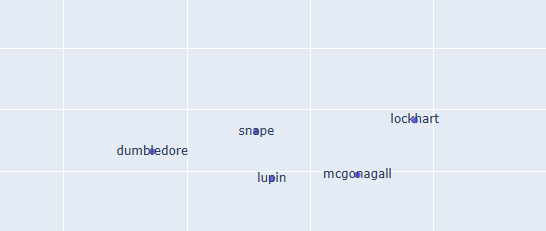

Hay un pequeño cluster conformado por "hogwarts" y "school". Si bien se explica solo, vale la pena mencionarlo, los alumnos asisten al Colegio Hogwarts de magia y hechicería
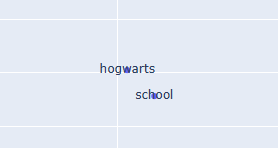

Otro pequeño cluster está conformado por "gryffindor" y "slytherin". Es normal, el colegio reparte a los alumnos en cuatro casas: "gryffindor", "hufflepuff", "ravenclaw" y "slytherin". Particularmente, estas dos, tienen la fama de ser las casas "rivales".
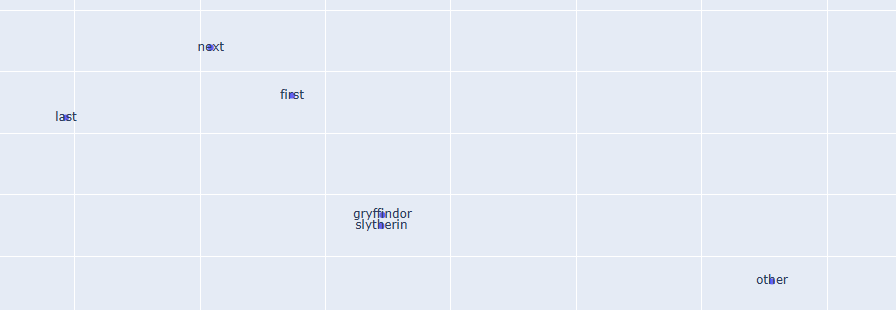

Este cluster no tiene mucho contexto histórico, está conformado por contracciones negativas.
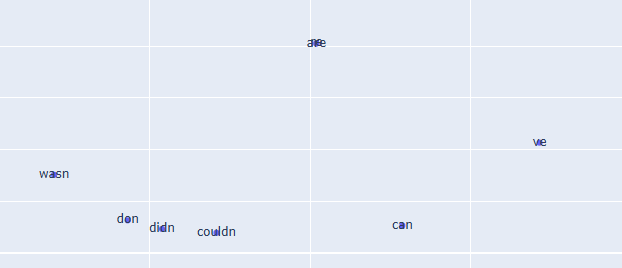

Por último, el siguiente cluster contiene palabras como "wand", "hand", "head" y "face". Varita y mano tienen sentido que aparezcan juntas, muchas veces en los libros se hace mención al hecho de pensar hechizos o usar la cabeza antes de actuar, entonces tiene sentido que aparezcan juntas
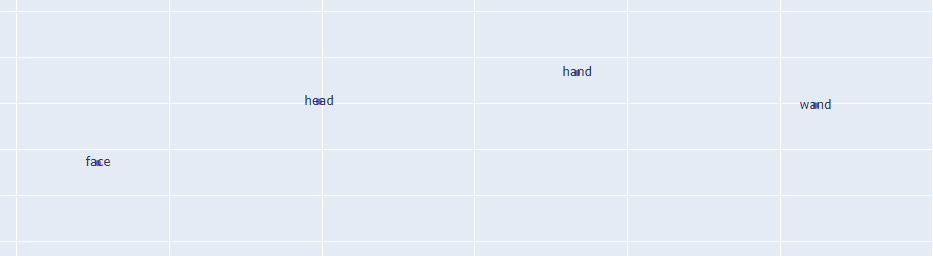

## Cierre

Para este último item del notebook, dado que se tiene un vocabulario extenso hubiese sido útil utilizar un MAX_WORDS de 500 o más ya que muchos términos son personajes distintos de las historias, pero el gráfico se volvía algo engorroso de visualizar. Más allá de eso, cuando se agrega una mayor cantidad de palabras al gráfico, los clusters respetan su tipología, es decir, aparecen términos del mismo contexto. Por ejemplo en el clusters de profesores aparecían palabras como "trelawney", "quirrel", etc. Preferí utilizar un MAX_WORDS de 200 para visualizar aquellos clusters cuyos términos presentan mayor frecuencia.

Si bien el vocabulario utilizado para los libros no es técnicamente complejo, se utiliza una amplia variedad de términos en la redacción, es decir, es ríco en vocabulario. Hay muchos términos que probablemente quedaron afuera ya que hacen referencia a nombres propios de personajes o nombres de objetos, lugares, etc que no tienen suficiente peso con respecto a palabras comunes.